# 02 Hand-crafted features and the mean-colour baseline

**Owner:** Ayesha. **Runs in:** about 2 minutes for all 8,189 images on 4 CPU cores.

Each image becomes:

| Block | Values | What it captures |
|---|---|---|
| RGB histogram | 3 x 32 = 96 | how much of each red / green / blue level |
| HSV histogram | 3 x 32 = 96 | hue (which colour), saturation (how vivid), value (how bright) |
| LBP histogram | 59 | local texture: edges, spots, flat areas |
| Mean colour | 3 | average R, G, B; the simple baseline |

Two hand-crafted representations are compared: **RGB + LBP** and **HSV + LBP** (155 values each). Every value is then standardised (mean 0, spread 1) using train+val only, so colour and texture count equally.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from p22 import config, data
pd.set_option("display.precision", 3)
from skimage.color import rgb2hsv
from skimage.feature import local_binary_pattern
from p22 import handcrafted

## 1. One image, step by step

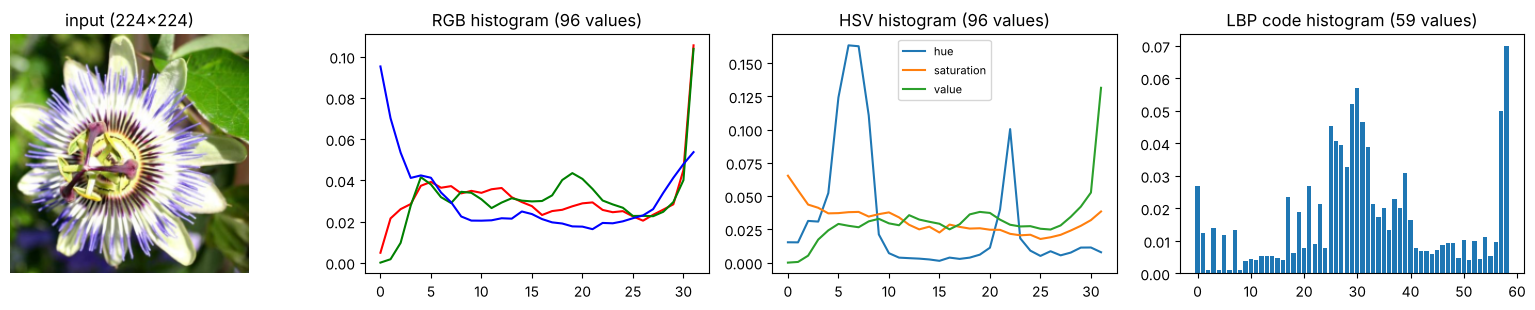

In [2]:
img = data.load_image(data.image_paths()[0])
f = handcrafted.features_for_image(data.image_paths()[0])
fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
ax[0].imshow(img); ax[0].set_title("input (224x224)"); ax[0].axis("off")
for c, col in enumerate("rgb"):
    ax[1].plot(f["rgb_hist"][c * 32:(c + 1) * 32], color=col)
ax[1].set_title("RGB histogram (96 values)")
for c, name in enumerate(["hue", "saturation", "value"]):
    ax[2].plot(f["hsv_hist"][c * 32:(c + 1) * 32], label=name)
ax[2].legend(fontsize=8); ax[2].set_title("HSV histogram (96 values)")
ax[3].bar(range(59), f["lbp"]); ax[3].set_title("LBP code histogram (59 values)")
plt.tight_layout()

### What LBP looks at
Each pixel is compared with its 8 neighbours (brighter or darker), giving an 8-bit pattern. "Uniform" patterns, with at most two changes around the circle, are edges, corners and flat spots. Each gets its own code (58 codes), and all the rest share one code, giving 59 bins (Ojala et al., 2002).

(np.float64(-0.5), np.float64(223.5), np.float64(223.5), np.float64(-0.5))

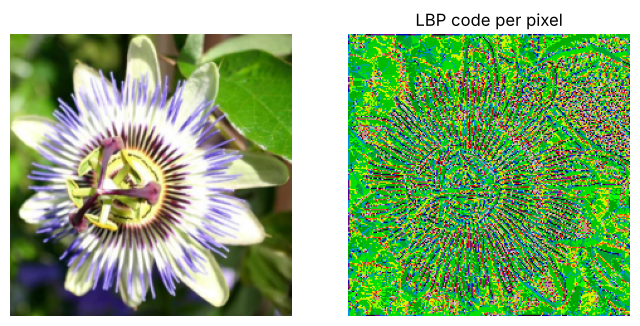

In [3]:
from skimage.color import rgb2gray
codes = local_binary_pattern((rgb2gray(img) * 255).astype(np.uint8), 8, 1, method="nri_uniform")
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(img); ax[0].axis("off")
ax[1].imshow(codes, cmap="nipy_spectral"); ax[1].set_title("LBP code per pixel"); ax[1].axis("off")

## 2. All images
Set `RECOMPUTE = True` to extract again (about 2 minutes); otherwise the cached files from `scripts/extract_features.py` are loaded.

In [4]:
RECOMPUTE = False
if RECOMPUTE:
    blocks = handcrafted.extract(data.image_paths())
else:
    blocks = {k: np.load(config.FEATURES_DIR / f"{k}.npy") for k in ["rgb_hist", "hsv_hist", "lbp", "mean_rgb"]}
{k: v.shape for k, v in blocks.items()}

{'rgb_hist': (8189, 96),
 'hsv_hist': (8189, 96),
 'lbp': (8189, 59),
 'mean_rgb': (8189, 3)}

## 3. Sanity checks
Histograms sum to 1 per channel (so 3 for the colour blocks), and there are no missing values.

In [5]:
print("RGB sums:", np.unique(blocks["rgb_hist"].sum(1).round(4)))
print("LBP sums:", np.unique(blocks["lbp"].sum(1).round(4)))
print("any NaN:", any(np.isnan(v).any() for v in blocks.values()))

RGB sums: [3.]
LBP sums: [1.]
any NaN: False
